# Assignment 1: Data Profiling (EDA) Report

**Topic:** Data Quality Profiling of Hustle Culture Discussions on X (Twitter)  
**Course:** TTTC3213 Data Engineering

| Name | Matric number |
|---|---|
| WANG JUNRU | A207389 |
| FU SHENGLIN | A207876 |
| MENG ZHUOJIA | A207327 |
| WANG HAOYU | A207345 |

**How to run:** Keep `Assignment_1_Hustle_Culture_EDA_Excellent.ipynb` and `hustle_culture_tweets.csv` in the same directory. Install `pandas`, `numpy`, `matplotlib`, and `seaborn` if necessary, then select **Run All** in Jupyter. In Colab, upload the CSV to the current working directory first. No API credentials are needed. The notebook does not overwrite the source CSV.

**Purpose:** Diagnose data quality problems, show justified handling decisions, and evaluate remaining risks. This is not a sentiment-modeling or audience-insights report.

## 1. Scenario

Our group previously collected public X posts about hustle culture, including discussions of burnout and work pressure. The data may contain missing optional fields, repeated text, highly skewed engagement counts, and identifiable user details. We examine which problems require cleaning, which values should be preserved, and whether the resulting dataset is suitable for limited research.

## 2. Data Source and Reproducibility

**Platform:** [X (formerly Twitter)](https://x.com/). **Dataset:** `hustle_culture_tweets.csv`, collected for our previous-semester group project using the API and collection procedure supplied by our lecturer, Lailatul Qadri. The group confirms that the records are real collected posts, not synthetic records. The original file contains individual `tweet_url` values that link back to their posts.

The previous project describes search terms including `hustle culture`, `rise and grind`, `996`, `grind mindset`, `self made`, `burnout`, `antiwork`, `quiet quitting`, and `toxic productivity`, and a March–June 2026 collection window. This notebook uses the **599-row original CSV**, not the separate 587-row sentiment-enriched file. Exact API requests, pagination settings, and retrieval timestamp are not preserved here, so the original collection cannot be reproduced from this notebook alone. Engagement counts are snapshots and may have changed since collection.

**Source reference:** [X platform](https://x.com/); per-post links are stored in `tweet_url` in the original CSV. The original project notebook `final_HUSTLE_GP2.ipynb` documents the earlier collection project. No API token or secret is included in this submission.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
raw = pd.read_csv("hustle_culture_tweets.csv", dtype={"id_str": "string", "user_id_str": "string", "conversation_id_str": "string"})
print("Original shape:", raw.shape)
display(raw.head(3)[["created_at", "lang", "favorite_count", "reply_count"]])

Original shape: (599, 15)


,created_at,lang,favorite_count,reply_count
0,2026-03-05T10:02:25.000Z,en,15,10
1,2026-03-07T00:43:53.000Z,en,9,1
2,2026-03-04T18:28:22.000Z,en,23,15


## 3. Data Profiling and Issue Handling

### 3.1 Initial profile

We inspect missingness, data types, distinct values, duplicate IDs, invalid dates, and numeric engagement values **before** changing the data. A missing optional field is not automatically an error.

In [2]:
profile = pd.DataFrame({"dtype": raw.dtypes.astype(str), "non_null": raw.notna().sum(), "missing": raw.isna().sum(), "missing_pct": (raw.isna().mean() * 100).round(2), "unique": raw.nunique(dropna=True)})
display(profile)
engagement_cols = ["favorite_count", "retweet_count", "reply_count", "quote_count"]
initial_checks = pd.Series({
    "Exact duplicate rows": int(raw.duplicated().sum()),
    "Duplicate tweet IDs": int(raw["id_str"].duplicated().sum()),
    "Repeated text (not necessarily duplicate posts)": int(raw["full_text"].duplicated().sum()),
    "Unparseable UTC timestamps": int(pd.to_datetime(raw["created_at"], errors="coerce", utc=True).isna().sum()),
    "Missing tweet IDs": int(raw["id_str"].isna().sum()),
    "Missing post text": int(raw["full_text"].isna().sum()),
    "Invalid numeric engagement cells": int(sum(pd.to_numeric(raw[c], errors="coerce").isna().sum() for c in engagement_cols)),
    "Negative engagement cells": int(sum((pd.to_numeric(raw[c], errors="coerce") < 0).sum() for c in engagement_cols))
}, name="before")
display(initial_checks.to_frame())

,dtype,non_null,missing,missing_pct,unique
conversation_id_str,string,599,0,0.00,572
created_at,object,599,0,0.00,599
favorite_count,int64,599,0,0.00,93
full_text,object,599,0,0.00,594
id_str,string,599,0,0.00,599
image_url,object,84,515,85.98,84
in_reply_to_screen_name,object,246,353,58.93,225
lang,object,599,0,0.00,11
location,float64,0,599,100.00,0
quote_count,int64,599,0,0.00,15


,before
Exact duplicate rows,0
Duplicate tweet IDs,0
Repeated text (not necessarily duplicate posts),5
Unparseable UTC timestamps,0
Missing tweet IDs,0
Missing post text,0
Invalid numeric engagement cells,0
Negative engagement cells,0


### 3.2 Cleaning decisions

- **Missing `location`:** All 599 values are missing. Remove the column from the working copy; inventing locations would mislead analysis.
- **Missing `image_url` and `in_reply_to_screen_name`:** These fields can legitimately be blank when a post has no image or is not a reply. Preserve missing values and add `has_image` and `has_reply_target` indicators. Do not impute URLs or usernames.
- **Duplicates:** Remove exact duplicate rows and duplicate non-null tweet IDs if present, keeping the first record. Repeated text with different tweet IDs is not automatically a duplicate; keep it.
- **Types and validity:** Load identifiers as strings, parse timestamps in UTC, and coerce engagement counts to numeric. Treat negative counts as invalid/missing, rather than replacing them with zero. Drop rows without a usable tweet ID, text, or timestamp because they cannot be reliably identified or dated. This dataset currently has no such rows.
- **No indiscriminate filling:** There is no defensible value with which to fill a missing user location, media URL, or reply target.

In [3]:
df = raw.copy()
df = df.drop_duplicates().drop_duplicates(subset=["id_str"], keep="first")
df["has_image"] = df["image_url"].notna()
df["has_reply_target"] = df["in_reply_to_screen_name"].notna()
df["created_at_utc"] = pd.to_datetime(df["created_at"], errors="coerce", utc=True)
for col in engagement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col] < 0, col] = np.nan
removed_invalid_core = int((df["id_str"].isna() | df["full_text"].isna() | df["created_at_utc"].isna()).sum())
df = df.dropna(subset=["id_str", "full_text", "created_at_utc"]).copy()
df = df.drop(columns=["location"])
print("Cleaned shape:", df.shape)
print("Rows dropped for invalid core fields:", removed_invalid_core)
print("Original row count:", len(raw), "Retained row count:", len(df))

Cleaned shape: (599, 17)
Rows dropped for invalid core fields: 0
Original row count: 599 Retained row count: 599


### 3.3 Outlier detection and handling

Use the IQR rule on `favorite_count`: values above `Q3 + 1.5 × IQR` are flagged. A very popular post is not necessarily a data-entry mistake, so we **keep and flag** extreme values instead of deleting or capping them. This avoids changing genuine observed engagement. For comparisons, medians or log-scaled plots are more robust than an unqualified mean. IQR is a diagnostic rule, not proof that a value is false.

In [4]:
q1 = df["favorite_count"].quantile(0.25)
q3 = df["favorite_count"].quantile(0.75)
iqr = q3 - q1
lower = max(0, q1 - 1.5 * iqr)
upper = q3 + 1.5 * iqr
df["likes_outlier_iqr"] = df["favorite_count"].notna() & ((df["favorite_count"] < lower) | (df["favorite_count"] > upper))
print(f"Q1={q1:g}, Q3={q3:g}, IQR={iqr:g}, lower={lower:g}, upper={upper:g}")
print("Flagged posts:", int(df["likes_outlier_iqr"].sum()))
print("Median likes:", df["favorite_count"].median(), "Maximum likes:", df["favorite_count"].max())
print("Flagged rows retained:", int(df.loc[df["likes_outlier_iqr"], "favorite_count"].notna().sum()))
display(df[engagement_cols].describe().round(2))

Q1=0, Q3=10, IQR=10, lower=0, upper=25
Flagged posts: 79
Median likes: 2.0 Maximum likes: 14821.0
Flagged rows retained: 79


,favorite_count,retweet_count,reply_count,quote_count
count,599.00,599.00,599.00,599.00
mean,97.44,10.88,3.37,0.65
std,811.44,117.15,16.79,5.32
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,2.00,0.00,0.00,0.00
75%,10.00,1.00,1.00,0.00
max,14821.00,2607.00,224.00,98.00


### 3.4 Before vs After: evidence of the fixes

This table separates **actual errors** from **legitimate missing optional values**. Retained blanks in optional fields are intentional, not failed cleaning. Outliers remain in the data with an explicit flag. A zero initial error count is also a valid result of a quality check.

In [5]:
after_checks = pd.Series({
    "Exact duplicate rows": int(df.duplicated(subset=raw.columns.drop("location").tolist()).sum()),
    "Duplicate tweet IDs": int(df["id_str"].duplicated().sum()),
    "Repeated text (not necessarily duplicate posts)": int(df["full_text"].duplicated().sum()),
    "Unparseable UTC timestamps": int(df["created_at_utc"].isna().sum()),
    "Missing tweet IDs": int(df["id_str"].isna().sum()),
    "Missing post text": int(df["full_text"].isna().sum()),
    "Invalid numeric engagement cells": int(sum(df[c].isna().sum() for c in engagement_cols)),
    "Negative engagement cells": int(sum((df[c] < 0).sum() for c in engagement_cols))
}, name="after")
comparison = pd.concat([initial_checks, after_checks], axis=1)
comparison["decision"] = ["Remove if found", "Deduplicate by ID", "Keep distinct posts", "Drop invalid core rows", "Drop invalid core rows", "Drop invalid core rows", "Mark missing, never invent counts", "Set invalid values to missing"]
display(comparison)
optional_summary = pd.DataFrame({"before_missing": raw[["location", "image_url", "in_reply_to_screen_name"]].isna().sum(), "handling": ["Remove entirely empty column", "Keep null; add has_image", "Keep null; add has_reply_target"]})
display(optional_summary)
print("Working data has location column:", "location" in df.columns)
print("Indicator fields created:", [c for c in ["has_image", "has_reply_target", "likes_outlier_iqr"] if c in df.columns])

,before,after,decision
Exact duplicate rows,0,0,Remove if found
Duplicate tweet IDs,0,0,Deduplicate by ID
Repeated text (not necessarily duplicate posts),5,5,Keep distinct posts
Unparseable UTC timestamps,0,0,Drop invalid core rows
Missing tweet IDs,0,0,Drop invalid core rows
Missing post text,0,0,Drop invalid core rows
Invalid numeric engagement cells,0,0,"Mark missing, never invent counts"
Negative engagement cells,0,0,Set invalid values to missing


,before_missing,handling
location,599,Remove entirely empty column
image_url,515,Keep null; add has_image
in_reply_to_screen_name,353,Keep null; add has_reply_target


Working data has location column: False
Indicator fields created: ['has_image', 'has_reply_target', 'likes_outlier_iqr']


## 4. Exploratory Diagnostic Charts

These figures show **missingness, skewed extreme values, and sampling imbalance**. They are not intended to rank users or make population-level claims.

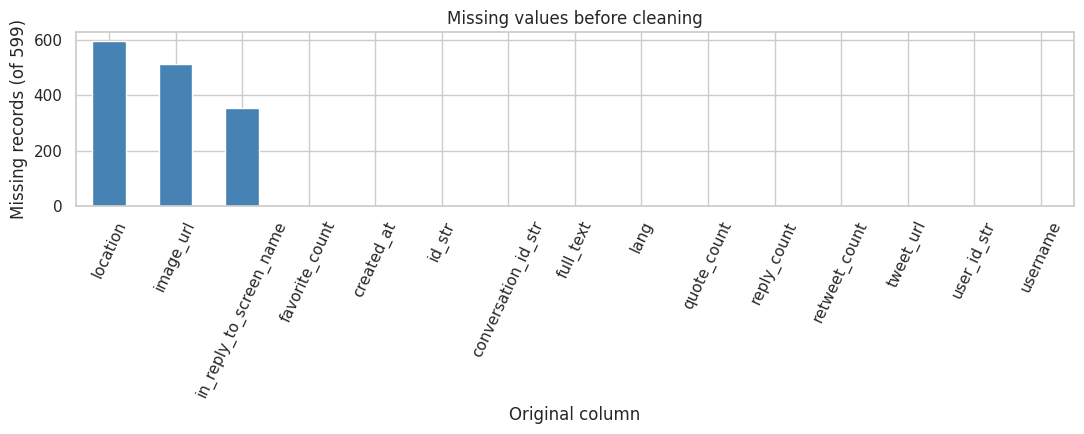

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
raw.isna().sum().sort_values(ascending=False).plot(kind="bar", ax=ax, color="steelblue")
ax.set(title="Missing values before cleaning", xlabel="Original column", ylabel="Missing records (of 599)")
ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

**Interpretation:** `location` is missing in every record, while the missing image and reply fields may simply describe posts without those features. We remove only the unusable location column and flag optional features.

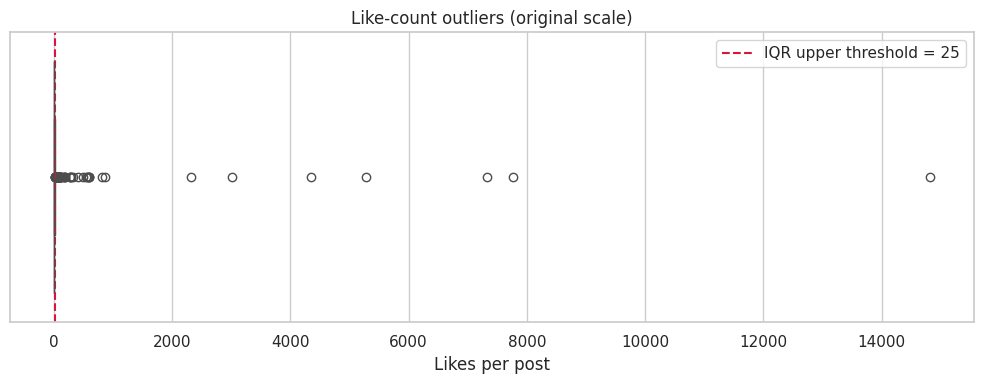

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=df["favorite_count"], ax=ax, color="orange")
ax.axvline(upper, color="crimson", linestyle="--", label=f"IQR upper threshold = {upper:g}")
ax.set(title="Like-count outliers (original scale)", xlabel="Likes per post")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** A small number of posts have far more likes than the typical post; the IQR flag records these extreme values without changing genuine counts.

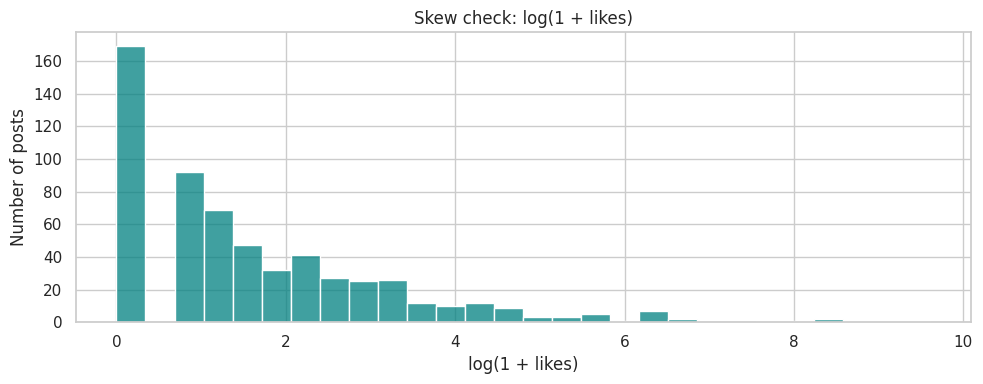

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(np.log1p(df["favorite_count"].dropna()), bins=28, ax=ax, color="teal")
ax.set(title="Skew check: log(1 + likes)", xlabel="log(1 + likes)", ylabel="Number of posts")
plt.tight_layout()
plt.show()

**Interpretation:** The log transformation reveals the spread of low-engagement posts that is compressed by extreme values on the raw scale; the underlying counts are not altered.

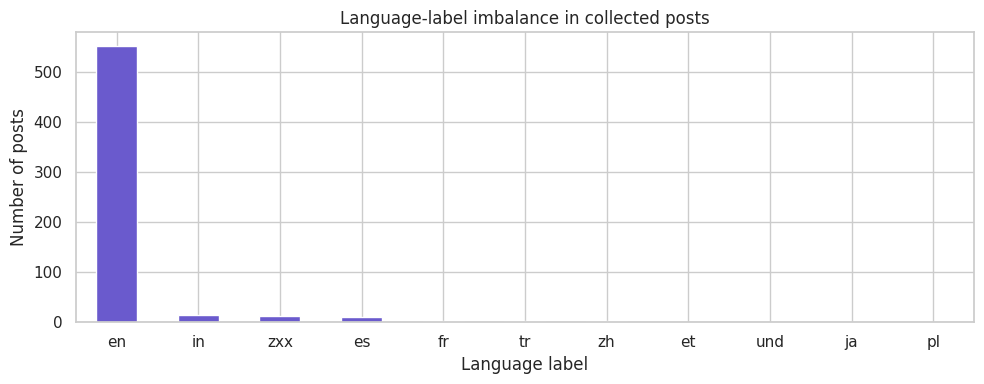

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
raw["lang"].fillna("missing").value_counts().plot(kind="bar", ax=ax, color="slateblue")
ax.set(title="Language-label imbalance in collected posts", xlabel="Language label", ylabel="Number of posts")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** English-labeled posts dominate the collected sample. This is a sampling limitation, not an error that should be fixed by inventing posts from other languages.

## 5. PII and Bias Risks

**PII and linkage risk:** `username`, `user_id_str`, `id_str`, `tweet_url`, `in_reply_to_screen_name`, and free-text content can identify or link back to people. Public availability does not remove privacy concerns. For an analysis-only view, drop direct identifiers and text, keep only aggregate-safe features, and avoid publishing individual examples. The original CSV is still identifiable: publishing it in a public GitHub repository requires a separate sharing/terms review. A reduced view is not a guarantee of anonymity.

**Sampling bias:** Keyword-based collection favors people using particular phrases; the search settings and exact retrieval window are not fully documented here. English-labeled posts account for most records, and highly engaged posts may be overrepresented depending on collection behavior. We should not generalize findings to all X users or all views on work culture. Mitigation would include documenting queries and dates, broadening language/keyword coverage in future collection, checking unique-user concentration, and reporting the sample composition. We do not manufacture balancing records.

In [10]:
privacy_columns = ["username", "user_id_str", "id_str", "conversation_id_str", "tweet_url", "full_text", "in_reply_to_screen_name", "image_url"]
analysis_view = df.drop(columns=privacy_columns, errors="ignore")
print("Original columns:", len(raw.columns), "Reduced analysis columns:", len(analysis_view.columns))
print("English-labeled records:", int(raw["lang"].eq("en").sum()), "of", len(raw))
print("English share: {:.1f}%".format(100 * raw["lang"].eq("en").mean()))
print("Unique user IDs:", raw["user_id_str"].nunique())
print("Largest number of posts from one user:", raw["user_id_str"].value_counts().max())
display(analysis_view.head(3))

Original columns: 15 Reduced analysis columns: 10
English-labeled records: 552 of 599
English share: 92.2%
Unique user IDs: 546
Largest number of posts from one user: 16


,created_at,favorite_count,lang,quote_count,reply_count,retweet_count,has_image,has_reply_target,created_at_utc,likes_outlier_iqr
0,2026-03-05T10:02:25.000Z,15.0,en,0.0,10.0,0.0,True,False,2026-03-05 10:02:25+00:00,False
1,2026-03-07T00:43:53.000Z,9.0,en,0.0,1.0,1.0,False,False,2026-03-07 00:43:53+00:00,False
2,2026-03-04T18:28:22.000Z,23.0,en,0.0,15.0,2.0,False,False,2026-03-04 18:28:22+00:00,False


## 6. Conclusion

The original 599-post dataset is suitable for a **limited, descriptive quality-controlled study** of the collected hustle-culture posts. Profiling found a completely empty location field, substantial missingness in optional media/reply fields, and highly skewed likes. We removed the unusable location column, preserved legitimate optional blanks with indicators, standardized types, checked identifiers and dates, and flagged extreme likes without deleting potentially real posts. The before/after checks show which problems were corrected and which values were deliberately kept.

Remaining limitations include unknown full API request settings, nonrepresentative keyword/language coverage, changing engagement counts, and privacy risks from identifiable public posts. The reduced analysis view helps limit direct identifiers, but the original CSV still requires careful sharing decisions. This dataset should not be used to estimate public opinion across all X users or to make claims about individual people.

**Submission check:** Keep this notebook and the original CSV in the same repository folder, ensure **Run All** works in a clean environment, and do not commit API tokens, passwords, `.env` files, or private credentials. The GitHub link must point to the notebook.